# 02 — Het CWF-model in detail

Deze notebook hoort bij [`docs/methodologie/cwf.md`](../docs/methodologie/cwf.md).
Het CWF-model (confidence-weighted forecast) beantwoordt per combinatie één vraag:

> *Welk deel van de mensen die nu in de pijplijn zitten, schrijft zich straks echt in?*

We rekenen het stap voor stap na voor één opleiding:

1. **Pijplijn en ratio** per eerder jaar
2. **Vulgraad**: hoe ver is de aanmeldcyclus?
3. **Ratiofactor en prior**: de twee schattingen
4. **Samenvoegen** tot één prognose
5. **Interval en label**
6. **Backtest** over meerdere jaren, vergeleken met "evenveel als vorig jaar"


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


In [2]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


## 1. De werkdata van het model

Het model zet de data eerst om naar één rij per combinatie × jaar × week, met drie
afgeleide kolommen:

| Kolom | Betekenis |
|-------|-----------|
| `Pipeline` | Gewogen vooraanmelders + inschrijvingen in die week |
| `Ratio` | Gerealiseerde instroom / pijplijn: welk deel van de pijplijn uiteindelijk instroomde |
| `Vulgraad` | Welk deel van de uiteindelijke aanmeldpiek op dat moment al bereikt was |

We bouwen die werkdata met dezelfde functies als het model zelf.


In [3]:
from studentprognose.config import load_defaults, get_final_academic_week
from studentprognose.models.cwf import CWFParams, ConfidenceWeightedForecast
from studentprognose.strategies.cumulative import prepare_cumulative_data
from studentprognose.strategies.cwf import build_cwf_history, redistribute_unknown_origin

config = load_defaults()
params = CWFParams.from_config(config)
final_week = get_final_academic_week(config)

data = redistribute_unknown_origin(prepare_cumulative_data(data_cumulative_raw.copy()))
studentcount = data_studentcount.copy()
studentcount["Croho groepeernaam"] = studentcount["Croho groepeernaam"].astype(data["Croho groepeernaam"].dtype)
history = build_cwf_history(data, studentcount, final_week, params.fill_rate_recency_alpha)

PROGRAMMA = 56604  # B Psychologie
HERKOMST = "NL"
EXAMENTYPE = "Bachelor"
PREDICT_YEAR = 2023
PREDICT_WEEK = 12

combo = history[
    (history["Croho groepeernaam"] == PROGRAMMA)
    & (history["Herkomst"] == HERKOMST)
    & (history["Examentype"] == EXAMENTYPE)
]
print(f"Combinatie: {label(PROGRAMMA, NAMEN)} · {HERKOMST} · {EXAMENTYPE}")
combo[combo["Weeknummer"] == PREDICT_WEEK][
    ["Collegejaar", "Pipeline", "Aantal_studenten", "Ratio", "Vulgraad"]
].set_index("Collegejaar").round(3)


Combinatie: 56604 B Psychologie · NL · Bachelor


,Pipeline,Aantal_studenten,Ratio,Vulgraad
Collegejaar,,,,
2020,1250.76,272.0,0.217,0.487
2021,1365.59,238.0,0.174,0.487
2022,998.59,229.0,0.229,0.503
2023,1286.66,253.0,0.197,0.479
2024,1075.25,254.0,0.236,0.484
2025,1353.83,300.0,0.222,0.485
2026,1088.75,NaN,NaN,0.494


De ratio zegt hoeveel van de pijplijn in week 12 uiteindelijk instroomde. Hoe
stabieler die ratio over de jaren, hoe betrouwbaarder het ratiosignaal. Voor het
voorspeljaar zelf is `Aantal_studenten` (en dus de ratio) nog onbekend: dat is wat
we voorspellen.

## 2. Vulgraad: hoe ver is de cyclus?

Vroeg in het jaar is de pijplijn nog klein en zegt hij weinig over de eindstand. De
**vulgraad** meet welk deel van de aanmeldpiek een opleiding in eerdere jaren op dit
moment al had bereikt. Hij wordt alleen uit **eerdere** jaren berekend, zodat het
model niet in de toekomst kijkt.


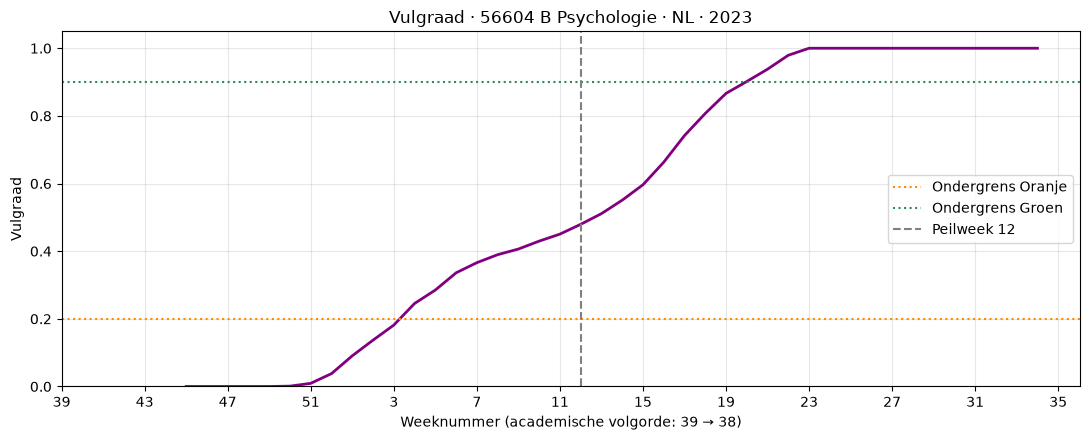

Vulgraad in week 12: 0.48


In [4]:
from studentprognose.utils.weeks import get_all_weeks_ordered

volgorde = get_all_weeks_ordered(final_week)
vj = combo[combo["Collegejaar"] == PREDICT_YEAR].copy()
vj["positie"] = vj["Weeknummer"].astype(str).map({w: i for i, w in enumerate(volgorde)})
vj = vj.dropna(subset=["positie"]).sort_values("positie")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(vj["positie"], vj["Vulgraad"], color="purple", linewidth=2)
ax.axhline(params.reliability_orange_min_fill, color="darkorange", linestyle=":", label="Ondergrens Oranje")
ax.axhline(params.reliability_green_min_fill, color="seagreen", linestyle=":", label="Ondergrens Groen")
ax.axvline(volgorde.index(str(PREDICT_WEEK)), color="gray", linestyle="--", label=f"Peilweek {PREDICT_WEEK}")
ax.set_xticks(range(0, len(volgorde), 4))
ax.set_xticklabels([volgorde[i] for i in range(0, len(volgorde), 4)])
ax.set_ylim(0, 1.05)
ax.set_xlabel("Weeknummer (academische volgorde: 39 → 38)")
ax.set_ylabel("Vulgraad")
ax.set_title(f"Vulgraad · {label(PROGRAMMA, NAMEN)} · {HERKOMST} · {PREDICT_YEAR}")
ax.legend()
plt.tight_layout()
plt.show()

VULGRAAD = float(vj.loc[vj["Weeknummer"] == PREDICT_WEEK, "Vulgraad"].iloc[0])
print(f"Vulgraad in week {PREDICT_WEEK}: {VULGRAAD:.2f}")


## 3. Ratiofactor en prior

Het model maakt twee schattingen:

1. **Het ratiosignaal**: de huidige pijplijn × de **ratiofactor**. De ratiofactor is
   een gemiddelde van de ratio's van eerdere jaren, met recente jaren zwaarder
   gewogen (meetkundig gemiddelde, zodat één uitschieter niet domineert). Bij weinig
   eigen jaren wordt hij getrokken naar de ratio van vergelijkbare opleidingen.
2. **De prior**: een schatting die alleen naar de gerealiseerde instroom kijkt.
   Meestal de instroom van vorig jaar; bij een duidelijke trend wordt een deel van
   die trend doorgetrokken.

We roepen het model aan met precies de historie die het in de pipeline krijgt.


In [5]:
week_slice = history[(history["Weeknummer"] == PREDICT_WEEK) & (history["Collegejaar"] < PREDICT_YEAR)]
groep = week_slice[(week_slice["Examentype"] == EXAMENTYPE) & (week_slice["Herkomst"] == HERKOMST)]
groep = groep[groep["Aantal_studenten"].notna()]
own = groep[groep["Croho groepeernaam"] == PROGRAMMA]
pool = groep[groep["Croho groepeernaam"] != PROGRAMMA]
pipeline_nu = float(combo.loc[(combo["Collegejaar"] == PREDICT_YEAR) & (combo["Weeknummer"] == PREDICT_WEEK), "Pipeline"].iloc[0])

model = ConfidenceWeightedForecast(params)
prior = model.get_prior(own["Aantal_studenten"], own["Collegejaar"].to_numpy(dtype=float), np.nan, True)
uit = model.predict(own=own, current_student_pipeline=pipeline_nu, pre_defined_prior=np.nan,
                    pool=pool, has_own_history=True, programme=PROGRAMMA)

signaal = pipeline_nu * uit["ratio_factor"]
print(f"Pijplijn nu (week {PREDICT_WEEK}, {PREDICT_YEAR}): {pipeline_nu:8.1f}")
print(f"Ratiofactor:                     {uit['ratio_factor']:8.2f}")
print(f"Ratiosignaal = pijplijn × factor: {signaal:8.1f}")
print(f"Prior (op basis van instroom):    {prior:8.1f}")
print(f"Gewicht van het ratiosignaal:     {uit['signal_weight']:8.2f}")


Pijplijn nu (week 12, 2023):   1286.7
Ratiofactor:                         0.20
Ratiosignaal = pijplijn × factor:    257.3
Prior (op basis van instroom):       218.3
Gewicht van het ratiosignaal:         0.50


## 4. Samenvoegen tot één prognose

$$\hat{y} = s \cdot (\text{pijplijn} \times R) + (1 - s) \cdot \text{prior}$$

Het gewicht $s$ is de vulgraad (gemiddeld over eerdere jaren), verlaagd als de
ratiofactor zelf onrustig is. Vroeg in de cyclus leunt de prognose dus op de prior,
laat in de cyclus op het ratiosignaal.


In [6]:
s = uit["signal_weight"]
handmatig = s * signaal + (1 - s) * prior
print(f"Handmatig: {s:.2f} × {signaal:.1f} + {1 - s:.2f} × {prior:.1f} = {handmatig:.1f}")
print(f"Model:     {uit['prediction']}")
print("(Klein verschil komt doordat de getoonde ratiofactor op twee decimalen is afgerond.)")


Handmatig: 0.50 × 257.3 + 0.50 × 218.3 = 237.7
Model:     240
(Klein verschil komt doordat de getoonde ratiofactor op twee decimalen is afgerond.)


## 5. Interval en label

Het model doet meer dan een puntschatting. Het **95%-interval** mengt twee bronnen
van onzekerheid:

- **Jaar-op-jaar**: hoe sterk de instroom van deze combinatie schommelt;
- **Trackrecord**: hoe ver het model er in eerdere jaren in dezelfde week naast zat
  (elk eerder jaar voorspeld met alleen de andere jaren).

Vroeg in de cyclus weegt de jaar-op-jaar-schommeling zwaarder, laat in de cyclus het
trackrecord. Het **label** vat samen hoe zeker de prognose is:

| Label | Wanneer |
|-------|---------|
| **Groen** | Vulgraad ≥ 0,9 en in alle eerdere jaren binnen ±16% (gemiddeld ±8%) |
| **Oranje** | Alles tussen Groen en Rood |
| **Rood** | Geen eigen historie, < 3 eigen backtestjaren, vulgraad < 0,2, of een eerder jaar met een fout van meer dan een factor 2 |

We draaien het model voor deze ene opleiding om prognose, interval en label te zien.


In [7]:
import os
from studentprognose.strategies.cwf import CWFStrategy
from _helpers import suppress_stdout
from studentprognose.utils.weeks import DataOption

strategy = CWFStrategy(data_cumulative_raw, data_studentcount, config, None, None,
                       os.getcwd(), DataOption.CWF, None)
strategy.preprocess()
strategy.set_filtering([PROGRAMMA], [], [EXAMENTYPE])
with suppress_stdout():
    een = strategy.predict_nr_of_students(PREDICT_YEAR, PREDICT_WEEK)

een = een.merge(
    data_studentcount[data_studentcount["Collegejaar"] == PREDICT_YEAR],
    on=["Croho groepeernaam", "Herkomst", "Examentype", "Collegejaar"], how="left",
)
een[["Herkomst", "Prognose_cwf", "cwf_ondergrens", "cwf_bovengrens",
     "cwf_betrouwbaarheid", "cwf_vulgraad", "cwf_ratiofactor", "Aantal_studenten"]]


,Herkomst,Prognose_cwf,cwf_ondergrens,cwf_bovengrens,cwf_betrouwbaarheid,cwf_vulgraad,cwf_ratiofactor,Aantal_studenten
0,EER,198.0,150.0,259.0,Oranje,0.467923,0.32,218
1,NL,240.0,198.0,291.0,Oranje,0.479417,0.20,253
2,Niet-EER,67.0,48.0,92.0,Oranje,0.505447,0.70,73


De rij voor NL hoort dezelfde prognose te geven als de handmatige berekening
hierboven. `Aantal_studenten` is de werkelijke instroom van 2023, ter vergelijking.

## 6. Backtest: hoe goed is het model over meerdere jaren?

Eén jaar zegt weinig. `backtest_cwf` voorspelt elk afgerond jaar vanaf dezelfde
peilweek, alsof het model toen live draaide. Dit is wat
`studentprognose benchmark -d cwf -w 12` ook doet.

> 🕒 Duurt op de demodata ongeveer een minuut.


In [8]:
from studentprognose.benchmark.evaluate_cwf import backtest_cwf, summarise_cwf

with suppress_stdout():
    backtest = backtest_cwf(data_cumulative_raw, data_studentcount, config, PREDICT_WEEK)
per_jaar, per_label = summarise_cwf(backtest)

kolommen = {"n": "combinaties", "wape": "WAPE CWF", "naive_wape": "WAPE vorig jaar",
            "coverage": "binnen interval", "median_rel_width": "mediane breedte interval"}
per_jaar.rename(columns=kolommen)[["test_year", *kolommen.values()]].round(3)


,test_year,combinaties,WAPE CWF,WAPE vorig jaar,binnen interval,mediane breedte interval
0,alle,2004,0.145,0.211,0.937,0.870
1,2022,476,0.162,0.240,0.898,0.826
2,2023,512,0.142,0.226,0.906,0.857
3,2024,504,0.155,0.202,0.950,0.889
4,2025,512,0.126,0.182,0.990,0.900


Lees de tabel zo:

- **WAPE CWF lager dan WAPE vorig jaar**: het model voegt iets toe boven
  "evenveel als vorig jaar".
- **Binnen interval**: bij een goed 95%-interval ligt dit rond 0,95. Veel lager
  betekent dat het interval te smal is, veel hoger dat het te ruim is.
- **Mediane breedte**: de breedte van het interval als deel van de prognose.

Per label:


In [9]:
per_label.rename(columns=kolommen)[["label", *kolommen.values()]].round(3)


,label,combinaties,WAPE CWF,WAPE vorig jaar,binnen interval,mediane breedte interval
0,Oranje,753,0.128,0.204,0.956,0.708
1,Rood,1251,0.174,0.223,0.926,1.000


## 7. Wanneer vertrouw je het niet?

| Situatie | Wat te doen? |
|----------|--------------|
| **Label Rood** | Gebruik de prognose als indicatie; kijk naar het interval, niet naar één getal |
| **Vroeg in de cyclus** (lage vulgraad) | De prognose is vooral de instroom van vorig jaar |
| **Nieuwe opleiding** zonder historie | Stel een verwachte instroom in via `cwf_params.predefined_priors` |
| **Uitzonderlijk jaar** in de historie (bijv. corona) | Geef het minder gewicht via `cwf_params.year_weight_overrides`, bijv. `{"2021": 0.5}` |
| **Numerus fixus** | Het model kapt af op de capaciteit, maar weet niets van loting of selectie |

Alle parameters staan in `model_config.cwf_params`; zie de
[configuratiereferentie](../docs/configuratie-referentie.md#cwf_params).
